In [17]:
import pandas as pd
from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)


df_30_sec = pd.read_csv(DATA_PROCESSED / "features_30_sec.csv")
df_3_sec = pd.read_csv(DATA_PROCESSED / "features_3_sec.csv")

### Primeras 5 filas de `features_30_sec.csv`

In [18]:
display(df_30_sec.head())

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


### Primeras 5 filas de `3_sec.csv`

In [19]:
display(df_3_sec.head())

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


### Información de `df_30_sec`

In [21]:
print(df_30_sec.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 61 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   object 
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             

### Estadísticas descriptivas de `df_30_sec`

In [22]:
display(df_30_sec.describe())

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,length_in_seconds
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,662030.846000,0.378682,0.086340,0.130930,0.003051,2201.780898,4.696916e+05,2242.541070,137079.155165,4571.549304,...,60.730958,-3.966028,62.633624,0.507696,63.712586,-2.328761,66.231930,-1.095348,70.126096,30.024075
std,1784.073992,0.081705,0.007735,0.065683,0.003634,715.960600,4.008995e+05,526.316473,96455.666326,1574.791602,...,33.781951,4.549697,33.479172,3.869105,34.401977,3.755957,37.174631,3.837007,45.228512,0.080910
min,660000.000000,0.171939,0.044555,0.005276,0.000004,570.040355,7.911251e+03,898.066208,10787.185064,749.140636,...,9.169314,-17.234728,13.931521,-11.963694,15.420555,-18.501955,13.487622,-19.929634,7.956583,29.931973
25%,661504.000000,0.319562,0.082298,0.086657,0.000942,1627.697311,1.843505e+05,1907.240605,67376.554428,3380.069642,...,40.376442,-7.207225,40.830875,-2.007015,41.884240,-4.662925,41.710184,-3.368996,42.372865,30.000181
50%,661794.000000,0.383148,0.086615,0.122443,0.001816,2209.263090,3.384862e+05,2221.392843,111977.548036,4658.524473,...,52.325077,-4.065605,54.717674,0.669643,54.804890,-2.393862,57.423059,-1.166289,59.186117,30.013333
75%,661794.000000,0.435942,0.091256,0.175682,0.003577,2691.294667,6.121479e+05,2578.469836,182371.576801,5533.810460,...,71.691755,-0.838737,75.040838,3.119212,75.385832,0.150573,78.626444,1.312615,85.375374,30.013333
max,675808.000000,0.663685,0.108111,0.397973,0.027679,4435.243901,3.036843e+06,3509.646417,694784.811549,8677.672688,...,392.932373,11.482946,406.058868,15.388390,332.905426,14.694924,393.161987,15.369627,506.065155,30.648889


### Información de `df_3_sec`

In [23]:
print(df_3_sec.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9990 entries, 0 to 9989
Data columns (total 61 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 9990 non-null   object 
 1   length                   9990 non-null   int64  
 2   chroma_stft_mean         9990 non-null   float64
 3   chroma_stft_var          9990 non-null   float64
 4   rms_mean                 9990 non-null   float64
 5   rms_var                  9990 non-null   float64
 6   spectral_centroid_mean   9990 non-null   float64
 7   spectral_centroid_var    9990 non-null   float64
 8   spectral_bandwidth_mean  9990 non-null   float64
 9   spectral_bandwidth_var   9990 non-null   float64
 10  rolloff_mean             9990 non-null   float64
 11  rolloff_var              9990 non-null   float64
 12  zero_crossing_rate_mean  9990 non-null   float64
 13  zero_crossing_rate_var   9990 non-null   float64
 14  harmony_mean            

### Estadísticas descriptivas de `df_3_sec`

In [24]:
display(df_3_sec.describe())

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,length_in_seconds
count,9990.0,9990.000000,9990.000000,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,...,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9.990000e+03
mean,66149.0,0.379534,0.084876,0.130859,2.676388e-03,2199.219431,4.166727e+05,2241.385959,1.182711e+05,4566.076592,...,49.988755,-4.198706,51.962753,0.739943,52.488851,-2.497306,54.973829,-0.917584,57.322614,2.999955e+00
std,0.0,0.090466,0.009637,0.068545,3.585628e-03,751.860611,4.349644e+05,543.854449,1.013505e+05,1642.065335,...,34.442816,5.677379,36.400669,5.181313,38.177120,5.111799,41.585677,5.253243,46.444212,5.866712e-13
min,66149.0,0.107108,0.015345,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.183520e+03,658.336276,...,1.325786,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,0.282131,2.999955e+00
25%,66149.0,0.315698,0.079833,0.083782,6.145900e-04,1630.680158,1.231961e+05,1887.455790,4.876553e+04,3378.311110,...,29.584894,-7.951722,29.863448,-2.516638,29.636197,-5.734123,30.496412,-4.004475,30.011365,2.999955e+00
50%,66149.0,0.384741,0.085108,0.121253,1.491318e-03,2208.628236,2.650692e+05,2230.575595,8.996072e+04,4631.377892,...,41.702393,-4.443021,42.393583,0.733772,41.831377,-2.702366,43.435253,-1.030939,44.332155,2.999955e+00
75%,66149.0,0.442443,0.091092,0.176328,3.130862e-03,2712.581884,5.624152e+05,2588.340505,1.585674e+05,5591.634521,...,59.274619,-0.726945,61.676964,3.888734,62.033906,0.514246,65.328602,2.216603,68.210421,2.999955e+00
max,66149.0,0.749481,0.120964,0.442567,3.261522e-02,5432.534406,4.794119e+06,3708.147554,1.235143e+06,9487.446477,...,683.932556,34.048843,529.363342,36.970322,629.729797,31.365425,1143.230591,34.212101,910.473206,2.999955e+00


### Comparación de Tipos de Datos y Conteo de Valores No Nulos

In [26]:
info_30_sec = pd.DataFrame({
    'dtype_30_sec': df_30_sec.dtypes,
    'non_null_count_30_sec': df_30_sec.count()
})

info_3_sec = pd.DataFrame({
    'dtype_3_sec': df_3_sec.dtypes,
    'non_null_count_3_sec': df_3_sec.count()
})

# Unir las informaciones por el índice (nombre de la columna)
info_comparison = pd.concat([info_30_sec, info_3_sec], axis=1)

display(info_comparison)

,dtype_30_sec,non_null_count_30_sec,dtype_3_sec,non_null_count_3_sec
filename,object,1000,object,9990
length,int64,1000,int64,9990
chroma_stft_mean,float64,1000,float64,9990
chroma_stft_var,float64,1000,float64,9990
rms_mean,float64,1000,float64,9990
...,...,...,...,...
mfcc19_var,float64,1000,float64,9990
mfcc20_mean,float64,1000,float64,9990
mfcc20_var,float64,1000,float64,9990
label,object,1000,object,9990


### Comparación de Estadísticas Descriptivas entre `df_30_sec` y `df_3_sec`

In [25]:
# Obtener las estadísticas descriptivas de ambos DataFrames
desc_30_sec = df_30_sec.describe()
desc_3_sec = df_3_sec.describe()

# Renombrar los índices para identificar de qué DataFrame proviene cada columna
desc_30_sec.columns = [col + '_30_sec' for col in desc_30_sec.columns]
desc_3_sec.columns = [col + '_3_sec' for col in desc_3_sec.columns]

# Concatenar los DataFrames descriptivos
comparison_df = pd.concat([desc_30_sec, desc_3_sec], axis=1)

# Reordenar las columnas para que las de 30_sec y 3_sec de la misma característica estén juntas
base_cols = [col.replace('_30_sec', '') for col in desc_30_sec.columns]
ordered_cols = []
for base_col in base_cols:
    ordered_cols.append(base_col + '_30_sec')
    ordered_cols.append(base_col + '_3_sec')

comparison_df = comparison_df[ordered_cols]

display(comparison_df)

,length_30_sec,length_3_sec,chroma_stft_mean_30_sec,chroma_stft_mean_3_sec,chroma_stft_var_30_sec,chroma_stft_var_3_sec,rms_mean_30_sec,rms_mean_3_sec,rms_var_30_sec,rms_var_3_sec,...,mfcc19_mean_30_sec,mfcc19_mean_3_sec,mfcc19_var_30_sec,mfcc19_var_3_sec,mfcc20_mean_30_sec,mfcc20_mean_3_sec,mfcc20_var_30_sec,mfcc20_var_3_sec,length_in_seconds_30_sec,length_in_seconds_3_sec
count,1000.000000,9990.0,1000.000000,9990.000000,1000.000000,9990.000000,1000.000000,9990.000000,1000.000000,9.990000e+03,...,1000.000000,9990.000000,1000.000000,9990.000000,1000.000000,9990.000000,1000.000000,9990.000000,1000.000000,9.990000e+03
mean,662030.846000,66149.0,0.378682,0.379534,0.086340,0.084876,0.130930,0.130859,0.003051,2.676388e-03,...,-2.328761,-2.497306,66.231930,54.973829,-1.095348,-0.917584,70.126096,57.322614,30.024075,2.999955e+00
std,1784.073992,0.0,0.081705,0.090466,0.007735,0.009637,0.065683,0.068545,0.003634,3.585628e-03,...,3.755957,5.111799,37.174631,41.585677,3.837007,5.253243,45.228512,46.444212,0.080910,5.866712e-13
min,660000.000000,66149.0,0.171939,0.107108,0.044555,0.015345,0.005276,0.000953,0.000004,4.379535e-08,...,-18.501955,-27.448456,13.487622,3.065302,-19.929634,-35.640659,7.956583,0.282131,29.931973,2.999955e+00
25%,661504.000000,66149.0,0.319562,0.315698,0.082298,0.079833,0.086657,0.083782,0.000942,6.145900e-04,...,-4.662925,-5.734123,41.710184,30.496412,-3.368996,-4.004475,42.372865,30.011365,30.000181,2.999955e+00
50%,661794.000000,66149.0,0.383148,0.384741,0.086615,0.085108,0.122443,0.121253,0.001816,1.491318e-03,...,-2.393862,-2.702366,57.423059,43.435253,-1.166289,-1.030939,59.186117,44.332155,30.013333,2.999955e+00
75%,661794.000000,66149.0,0.435942,0.442443,0.091256,0.091092,0.175682,0.176328,0.003577,3.130862e-03,...,0.150573,0.514246,78.626444,65.328602,1.312615,2.216603,85.375374,68.210421,30.013333,2.999955e+00
max,675808.000000,66149.0,0.663685,0.749481,0.108111,0.120964,0.397973,0.442567,0.027679,3.261522e-02,...,14.694924,31.365425,393.161987,1143.230591,15.369627,34.212101,506.065155,910.473206,30.648889,2.999955e+00


### Diferencia Porcentual en las Estadísticas Descriptivas (`df_3_sec` vs `df_30_sec`)

In [27]:
import numpy as np

# 'base_cols' should already be defined from the previous cell or can be re-derived.
# For safety, let's re-derive it based on the desc_30_sec columns.
# (Excludes 'filename' as describe() only applies to numerical columns by default)
base_cols = [col.replace('_30_sec', '') for col in desc_30_sec.columns]

# Initialize an empty dictionary to store percentage differences
percentage_diff_data = {}
index_names = comparison_df.index

for base_col in base_cols:
    col_30_sec = base_col + '_30_sec'
    col_3_sec = base_col + '_3_sec'

    if col_30_sec in comparison_df.columns and col_3_sec in comparison_df.columns:
        val_30_sec = comparison_df[col_30_sec]
        val_3_sec = comparison_df[col_3_sec]

        # Calculate percentage difference, handling division by zero
        # If val_30_sec is 0:
        #   If val_3_sec is also 0, then 0% difference.
        #   If val_3_sec is not 0, then infinite difference (represented by np.inf).
        # Otherwise (val_30_sec is not 0), calculate normal percentage difference.
        pct_diff = np.where(
            val_30_sec == 0,
            np.where(val_3_sec == 0, 0.0, np.inf),
            ((val_3_sec - val_30_sec) / val_30_sec) * 100
        )
        percentage_diff_data[base_col + '_pct_diff'] = pct_diff

percentage_diff_df = pd.DataFrame(percentage_diff_data, index=index_names)
display(percentage_diff_df)

,length_pct_diff,chroma_stft_mean_pct_diff,chroma_stft_var_pct_diff,rms_mean_pct_diff,rms_var_pct_diff,spectral_centroid_mean_pct_diff,spectral_centroid_var_pct_diff,spectral_bandwidth_mean_pct_diff,spectral_bandwidth_var_pct_diff,rolloff_mean_pct_diff,...,mfcc16_var_pct_diff,mfcc17_mean_pct_diff,mfcc17_var_pct_diff,mfcc18_mean_pct_diff,mfcc18_var_pct_diff,mfcc19_mean_pct_diff,mfcc19_var_pct_diff,mfcc20_mean_pct_diff,mfcc20_var_pct_diff,length_in_seconds_pct_diff
count,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,...,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000,899.000000
mean,-90.008169,0.225087,-1.695249,-0.053962,-12.289826,-0.116336,-11.288019,-0.051509,-13.720571,-0.119712,...,-17.688183,5.866769,-17.036969,45.745139,-17.616198,7.237526,-16.997997,-16.229007,-18.257799,-90.008169
std,-100.000000,10.722585,24.579837,4.357712,-1.344661,5.014244,8.497121,3.332211,5.074660,4.271913,...,1.956268,24.785863,8.726313,33.915026,10.973622,36.098466,11.865741,36.909928,2.687907,-100.000000
min,-89.977424,-37.706030,-65.560173,-81.929352,-98.980169,-17.068742,-89.737637,-44.418028,-89.028460,-12.121137,...,-85.541056,61.359063,-88.339079,73.306081,-77.708719,48.354354,-77.273221,78.832482,-96.454115,-89.977424
25%,-90.000212,-1.209163,-2.995019,-3.317674,-34.731336,0.183256,-33.172890,-1.037353,-27.622409,-0.052027,...,-26.727338,10.329859,-26.860622,25.392088,-29.242607,22.972667,-26.884974,18.862569,-29.173150,-90.000212
50%,-90.004594,0.415761,-1.739529,-0.971697,-17.898835,-0.028736,-21.689791,0.413378,-19.661824,-0.582729,...,-20.301326,9.283137,-22.523053,9.576555,-23.672181,12.887312,-24.359215,-11.605179,-25.097037,-90.004594
75%,-90.004594,1.491380,-0.178866,0.367414,-12.473743,0.790966,-8.124292,0.382811,-13.052595,1.044923,...,-17.320173,-13.328595,-17.808802,24.670414,-17.711453,241.527058,-16.912684,68.869225,-20.105274,-90.004594
max,-90.211865,12.927241,11.888502,11.205112,17.831778,22.485584,57.865207,5.655873,77.773390,9.331693,...,74.058592,196.516610,30.366157,140.248152,89.161770,113.443937,190.778516,122.595519,79.912250,-90.211865


La elección entre el dataset de 30 segundos (df_30_sec) y el de 3 segundos (df_3_sec) para algoritmos de Machine Learning depende en gran medida del problema específico y los recursos disponibles. Aquí te presento una justificación basada en las comparaciones que hemos realizado:

**Argumentos a favor de usar df_3_sec (3 segundos):**

-Mayor Cantidad de Datos: df_3_sec tiene un número significativamente mayor de filas (9990 vs 1000). En general, los algoritmos de Machine Learning se benefician enormemente de tener más datos para entrenar, lo que puede llevar a modelos más robustos y con mejor capacidad de generalización, especialmente si los datos son representativos y las etiquetas están bien distribuidas.
-Granularidad Fina: Los segmentos de 3 segundos proporcionan una granularidad mucho más fina. Esto significa que el modelo puede aprender patrones y características que cambian más rápidamente dentro de una pieza de audio. Para tareas donde los detalles temporales son cruciales (por ejemplo, identificación de eventos musicales cortos, cambios de timbre rápidos), df_3_sec sería superior.
-Captura de Variabilidad: Al dividir los archivos en segmentos más pequeños, se captura una mayor variabilidad dentro de los datos de audio originales, lo que puede enriquecer el aprendizaje del modelo.

**Argumentos a favor de usar df_30_sec (30 segundos):**

-Representación Global: Si el objetivo es clasificar o analizar características generales de una pieza musical completa (ej. género musical de una canción entera), los promedios y varianzas calculados sobre 30 segundos podrían ser más representativos de la pieza como un todo, ignorando detalles transitorios.
-Menor Complejidad Computacional: Con solo 1000 entradas, df_30_sec requerirá menos tiempo y recursos computacionales para el entrenamiento y la inferencia del modelo. Esto puede ser una consideración importante cuando se trabaja con datasets muy grandes o con limitaciones de hardware.
-Menos Posible Ruido: Si los segmentos de 3 segundos introducen ruido o variaciones irrelevantes para la tarea (por ejemplo, silencios o transiciones que no aportan a la clasificación principal), los segmentos más largos podrían promediar o suavizar estos efectos.

### Conversión de 'length' de Muestras a Segundos

In [28]:
# Asumir una tasa de muestreo común para audio (ej. 22050 Hz)
SAMPLING_RATE = 22050

# Convertir 'length' de df_30_sec a segundos
df_30_sec['length_in_seconds'] = df_30_sec['length'] / SAMPLING_RATE

# Convertir 'length' de df_3_sec a segundos
df_3_sec['length_in_seconds'] = df_3_sec['length'] / SAMPLING_RATE

print("Primeras 5 filas de df_30_sec con 'length_in_seconds':")
display(df_30_sec[['length', 'length_in_seconds']].head())

print("\nPrimeras 5 filas de df_3_sec con 'length_in_seconds':")
display(df_3_sec[['length', 'length_in_seconds']].head())

Primeras 5 filas de df_30_sec con 'length_in_seconds':


,length,length_in_seconds
0,661794,30.013333
1,661794,30.013333
2,661794,30.013333
3,661794,30.013333
4,661794,30.013333



Primeras 5 filas de df_3_sec con 'length_in_seconds':


,length,length_in_seconds
0,66149,2.999955
1,66149,2.999955
2,66149,2.999955
3,66149,2.999955
4,66149,2.999955


### Histograma de la Duración de los Segmentos en Segundos

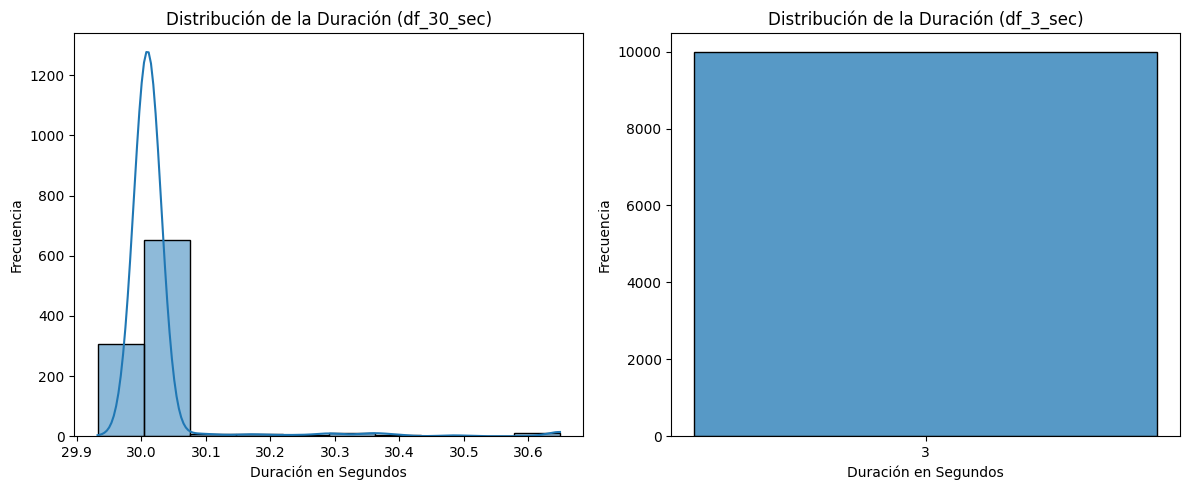

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_30_sec['length_in_seconds'], bins=10, kde=True)
plt.title('Distribución de la Duración (df_30_sec)')
plt.xlabel('Duración en Segundos')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
sns.histplot(df_3_sec['length_in_seconds'], bins=1, kde=False)
plt.title('Distribución de la Duración (df_3_sec)')
plt.xlabel('Duración en Segundos')
plt.ylabel('Frecuencia')
plt.xticks([df_3_sec['length_in_seconds'].iloc[0]]) # Mostrar solo el valor único

plt.tight_layout()
plt.show()

### Detección de Valores Duplicados por Columna

In [37]:
print("\n--- Duplicados en df_30_sec por columna ---")
for column in df_30_sec.columns:
    duplicates_count = df_30_sec[column].duplicated().sum()
    if duplicates_count > 0:
        print(f"Columna '{column}': {duplicates_count} valores duplicados")
    else:
        print(f"Columna '{column}': No hay valores duplicados")

print("\n--- Duplicados en df_3_sec por columna ---")
for column in df_3_sec.columns:
    duplicates_count = df_3_sec[column].duplicated().sum()
    if duplicates_count > 0:
        print(f"Columna '{column}': {duplicates_count} valores duplicados")
    else:
        print(f"Columna '{column}': No hay valores duplicados")


--- Duplicados en df_30_sec por columna ---
Columna 'filename': No hay valores duplicados
Columna 'length': 965 valores duplicados
Columna 'chroma_stft_mean': 14 valores duplicados
Columna 'chroma_stft_var': 14 valores duplicados
Columna 'rms_mean': 14 valores duplicados
Columna 'rms_var': 14 valores duplicados
Columna 'spectral_centroid_mean': 14 valores duplicados
Columna 'spectral_centroid_var': 14 valores duplicados
Columna 'spectral_bandwidth_mean': 14 valores duplicados
Columna 'spectral_bandwidth_var': 14 valores duplicados
Columna 'rolloff_mean': 14 valores duplicados
Columna 'rolloff_var': 14 valores duplicados
Columna 'zero_crossing_rate_mean': 16 valores duplicados
Columna 'zero_crossing_rate_var': 14 valores duplicados
Columna 'harmony_mean': 14 valores duplicados
Columna 'harmony_var': 14 valores duplicados
Columna 'perceptr_mean': 14 valores duplicados
Columna 'perceptr_var': 14 valores duplicados
Columna 'tempo': 965 valores duplicados
Columna 'mfcc1_mean': 14 valores d

###Análisis de la Distribución de la Variable Objetivo ('label')

Distribución de la variable 'label' en df_30_sec:


,count
label,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100



Distribución de la variable 'label' en df_3_sec:


,count
label,
blues,1000
jazz,1000
pop,1000
reggae,1000
metal,1000
disco,999
classical,998
hiphop,998
rock,998


/tmp/ipykernel_1557/3031054535.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_30_sec, x='label', palette='viridis')
/tmp/ipykernel_1557/3031054535.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_3_sec, x='label', palette='viridis')


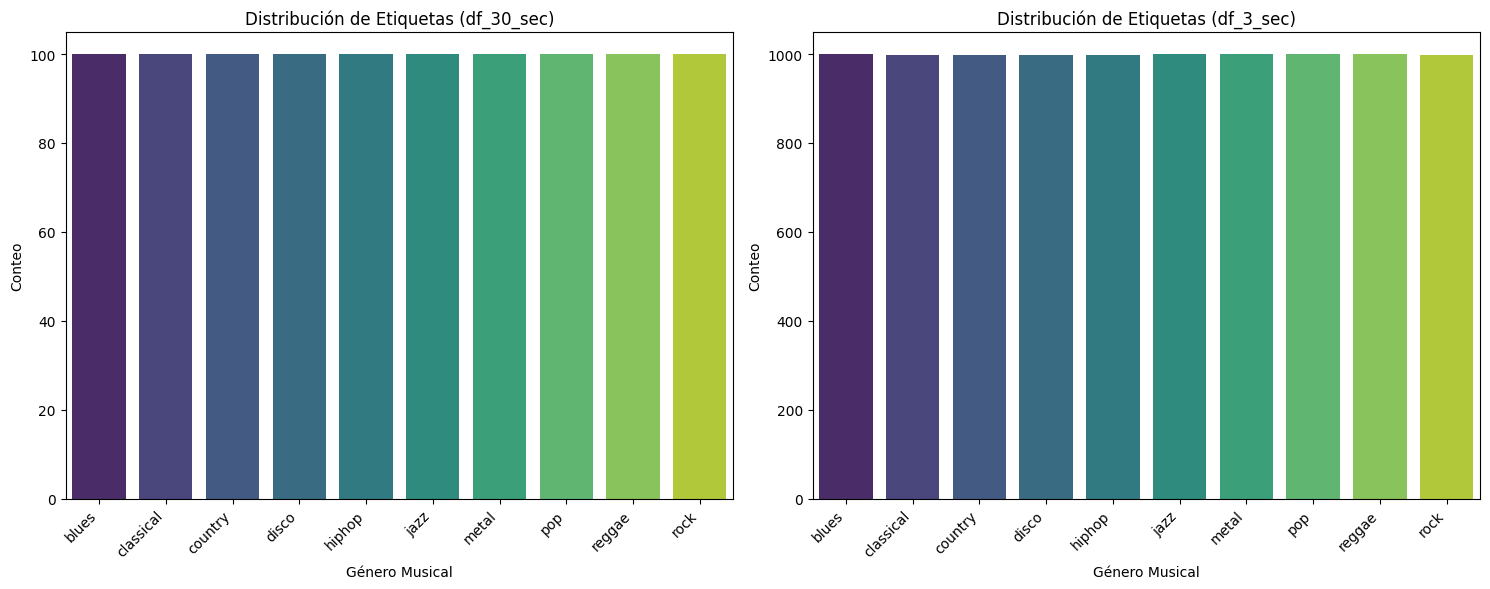

Observaciones sobre la distribución de la variable 'label':
- **Balance de Clases:** Verificamos si las clases están balanceadas en ambos datasets. Un balance similar es ideal para el entrenamiento de modelos de Machine Learning, ya que evita que el modelo se incline demasiado hacia la clase mayoritaria.
- **Consistencia de Clases:** Observamos si ambos datasets contienen las mismas categorías de etiquetas y en proporciones similares. Si df_3_sec se deriva directamente de df_30_sec, las proporciones deberían ser consistentes, aunque el número absoluto de instancias por clase será mayor en df_3_sec.


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Distribución de la variable 'label' en df_30_sec:")
display(df_30_sec['label'].value_counts())

print("\nDistribución de la variable 'label' en df_3_sec:")
display(df_3_sec['label'].value_counts())

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.countplot(data=df_30_sec, x='label', palette='viridis')
plt.title('Distribución de Etiquetas (df_30_sec)')
plt.xlabel('Género Musical')
plt.ylabel('Conteo')
plt.xticks(rotation=45, ha='right')

plt.subplot(1, 2, 2)
sns.countplot(data=df_3_sec, x='label', palette='viridis')
plt.title('Distribución de Etiquetas (df_3_sec)')
plt.xlabel('Género Musical')
plt.ylabel('Conteo')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print("Observaciones sobre la distribución de la variable 'label':")
print("- **Balance de Clases:** Verificamos si las clases están balanceadas en ambos datasets. Un balance similar es ideal para el entrenamiento de modelos de Machine Learning, ya que evita que el modelo se incline demasiado hacia la clase mayoritaria.")
print("- **Consistencia de Clases:** Observamos si ambos datasets contienen las mismas categorías de etiquetas y en proporciones similares. Si df_3_sec se deriva directamente de df_30_sec, las proporciones deberían ser consistentes, aunque el número absoluto de instancias por clase será mayor en df_3_sec.")

### Visualización de Datos con Reducción de Dimensionalidad (PCA)

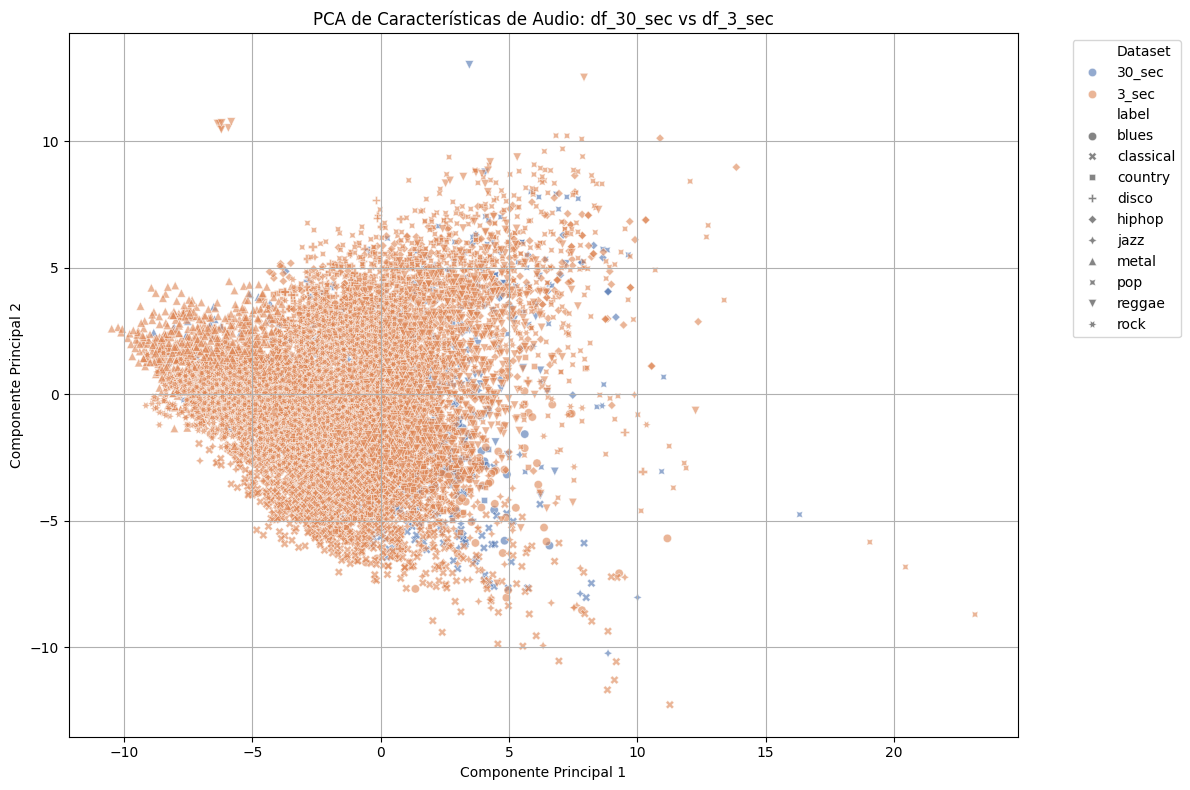


Observaciones sobre la visualización PCA:
- **Separación de Datasets:** Observa si los puntos de '30_sec' y '3_sec' forman grupos distintos o si se superponen. Una buena separación indicaría que las características de los segmentos de 30 segundos son inherentemente diferentes de las de 3 segundos incluso en un espacio de baja dimensión.
- **Agrupación por Género:** Dentro de cada grupo de dataset, ¿las diferentes etiquetas ('label') forman subgrupos? Esto nos daría una idea de la separabilidad de los géneros musicales en ambos conjuntos de datos.
Esta visualización es clave para entender la estructura global de tus datos y cómo la longitud del segmento afecta la representación de las características.


In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Excluir columnas no numéricas y las de 'length' para PCA
columns_to_exclude_for_pca = ['filename', 'label', 'original_filename', 'length', 'length_in_seconds']

# Preparar los DataFrames numéricos
X_30_sec = df_30_sec.drop(columns=columns_to_exclude_for_pca, errors='ignore')
X_3_sec = df_3_sec.drop(columns=columns_to_exclude_for_pca, errors='ignore')

# Asegurarse de que ambos DataFrames tengan las mismas columnas para la estandarización y PCA
common_cols = list(set(X_30_sec.columns) & set(X_3_sec.columns))
X_30_sec = X_30_sec[common_cols]
X_3_sec = X_3_sec[common_cols]

# Estandarizar los datos antes de aplicar PCA
scaler = StandardScaler()
X_30_sec_scaled = scaler.fit_transform(X_30_sec)
X_3_sec_scaled = scaler.transform(X_3_sec) # Usar el mismo scaler para df_3_sec

# Aplicar PCA a 2 componentes
pca = PCA(n_components=2)

principal_components_30_sec = pca.fit_transform(X_30_sec_scaled)
principal_components_3_sec = pca.transform(X_3_sec_scaled) # Aplicar la misma transformación

# Crear DataFrames con los componentes principales
pca_df_30_sec = pd.DataFrame(data=principal_components_30_sec, columns=['PC1', 'PC2'])
pca_df_30_sec['Dataset'] = '30_sec'
pca_df_30_sec['label'] = df_30_sec['label']

pca_df_3_sec = pd.DataFrame(data=principal_components_3_sec, columns=['PC1', 'PC2'])
pca_df_3_sec['Dataset'] = '3_sec'
pca_df_3_sec['label'] = df_3_sec['label']

# Concatenar para visualización conjunta
pca_combined_df = pd.concat([pca_df_30_sec, pca_df_3_sec])

# Visualizar los componentes principales
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=pca_combined_df,
    x='PC1',
    y='PC2',
    hue='Dataset', # Colorear por dataset para ver la separación
    style='label', # Usar el estilo para diferenciar las etiquetas
    palette='deep', # O 'viridis', 'plasma', etc.
    alpha=0.6
)
plt.title('PCA de Características de Audio: df_30_sec vs df_3_sec')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nObservaciones sobre la visualización PCA:")
print("- **Separación de Datasets:** Observa si los puntos de '30_sec' y '3_sec' forman grupos distintos o si se superponen. Una buena separación indicaría que las características de los segmentos de 30 segundos son inherentemente diferentes de las de 3 segundos incluso en un espacio de baja dimensión.")
print("- **Agrupación por Género:** Dentro de cada grupo de dataset, ¿las diferentes etiquetas ('label') forman subgrupos? Esto nos daría una idea de la separabilidad de los géneros musicales en ambos conjuntos de datos.")
print("Esta visualización es clave para entender la estructura global de tus datos y cómo la longitud del segmento afecta la representación de las características.")

### Análisis de Matrices de Correlación

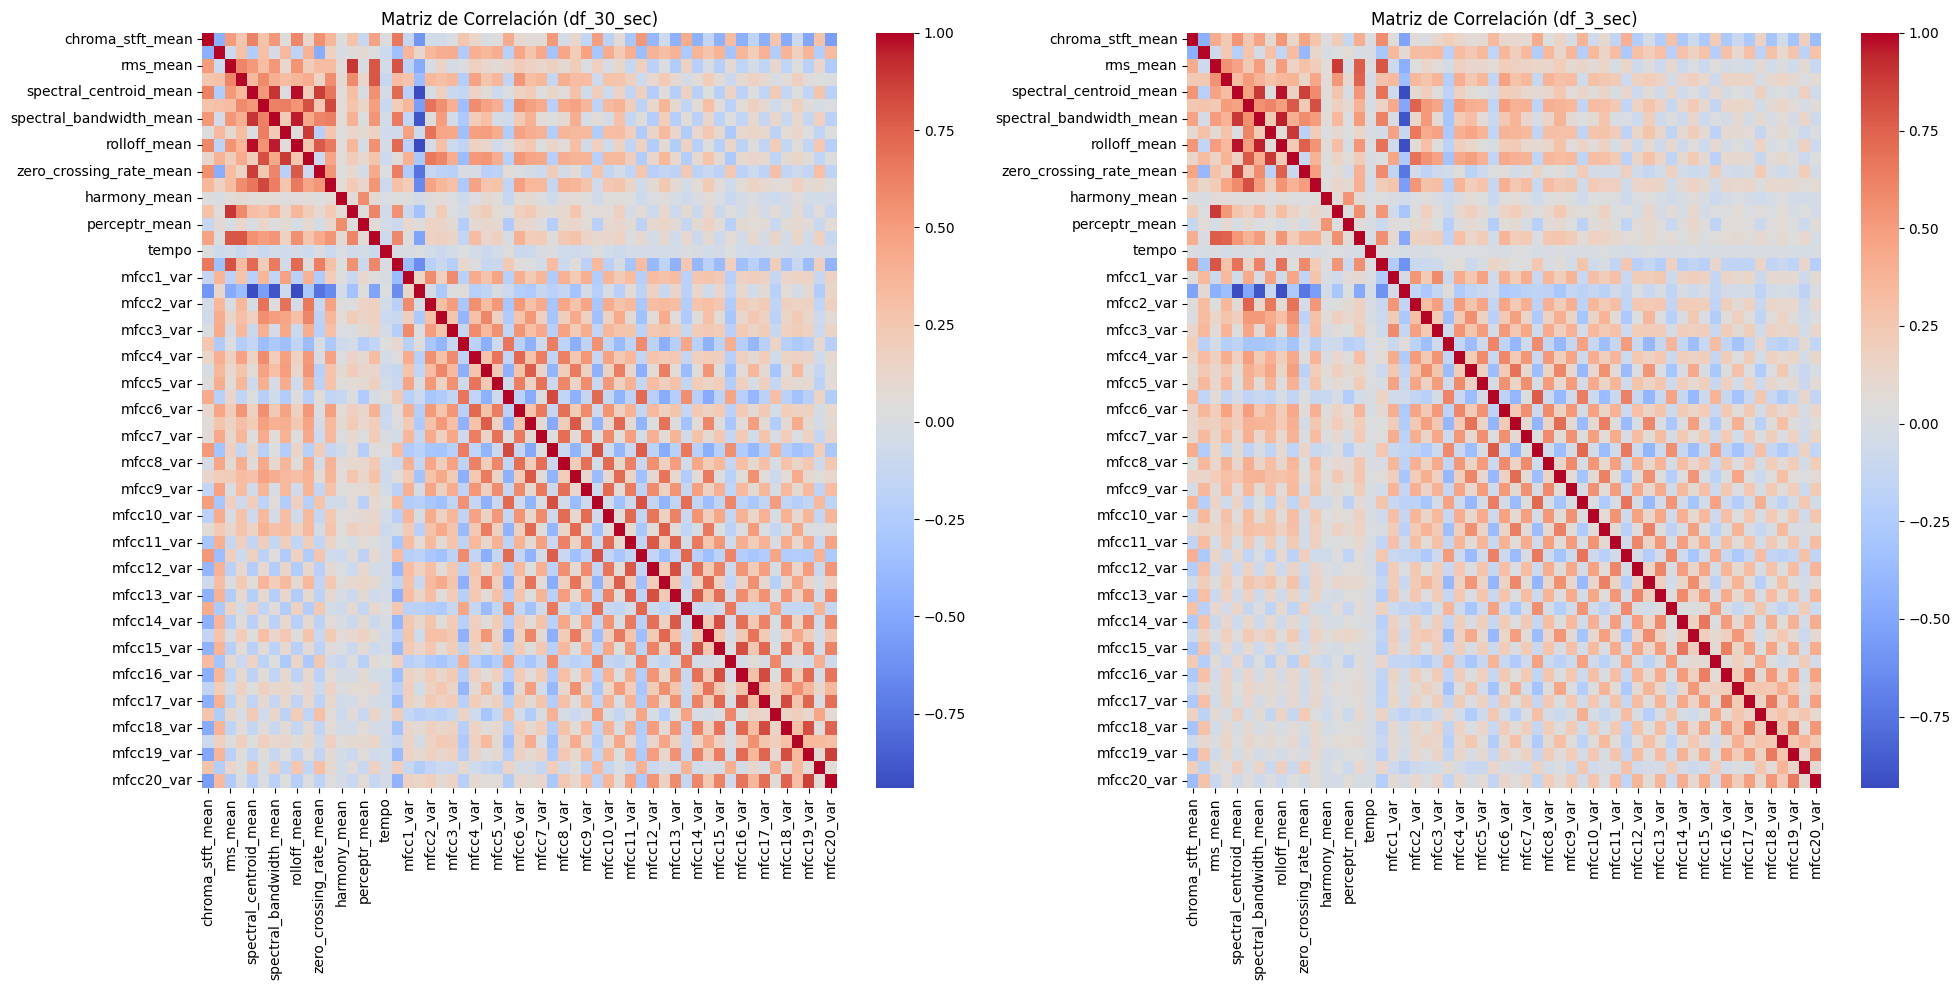

Observaciones sobre las matrices de correlación:
Visualizar estas matrices nos permitirá identificar patrones de correlación. Por ejemplo:
- **Correlaciones fuertes (colores intensos):** Indican que dos características tienden a aumentar o disminuir juntas (positiva) o una aumenta mientras la otra disminuye (negativa).
- **Correlaciones débiles (colores pálidos):** Sugieren poca o ninguna relación lineal entre las características.
Podemos buscar diferencias notables en la fuerza o dirección de las correlaciones entre los segmentos de 30 segundos y 3 segundos. Por ejemplo, algunas características pueden tener una correlación más fuerte o más débil en segmentos más cortos debido a la captura de eventos más transitorios.


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Excluir columnas no numéricas y las de 'length' si no se desea ver su correlación directa
columns_to_exclude = ['filename', 'label', 'original_filename', 'length', 'length_in_seconds']

df_30_sec_numeric = df_30_sec.drop(columns=columns_to_exclude, errors='ignore')
df_3_sec_numeric = df_3_sec.drop(columns=columns_to_exclude, errors='ignore')

# Calcular las matrices de correlación
corr_30_sec = df_30_sec_numeric.corr()
corr_3_sec = df_3_sec_numeric.corr()

plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
sns.heatmap(corr_30_sec, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Matriz de Correlación (df_30_sec)')

plt.subplot(1, 2, 2)
sns.heatmap(corr_3_sec, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Matriz de Correlación (df_3_sec)')

plt.tight_layout()
plt.show()

print("Observaciones sobre las matrices de correlación:")
print("Visualizar estas matrices nos permitirá identificar patrones de correlación. Por ejemplo:")
print("- **Correlaciones fuertes (colores intensos):** Indican que dos características tienden a aumentar o disminuir juntas (positiva) o una aumenta mientras la otra disminuye (negativa).")
print("- **Correlaciones débiles (colores pálidos):** Sugieren poca o ninguna relación lineal entre las características.")
print("Podemos buscar diferencias notables en la fuerza o dirección de las correlaciones entre los segmentos de 30 segundos y 3 segundos. Por ejemplo, algunas características pueden tener una correlación más fuerte o más débil en segmentos más cortos debido a la captura de eventos más transitorios.")

El resultado anterior muestra el número de valores duplicados para cada columna en `df_30_sec` y `df_3_sec`.

*   Es común ver duplicados en columnas como `length` o `length_in_seconds`, especialmente en `df_3_sec`, ya que todos los segmentos de 3 segundos tienen la misma duración.
*   La columna `filename` (o `original_filename` que creamos) suele tener menos duplicados o ninguno, ya que son identificadores únicos.
*   Para las características (como `chroma_stft_mean`, `rms_mean`, etc.), es posible encontrar duplicados si diferentes segmentos de audio o archivos tienen valores de características idénticos, lo cual puede ocurrir con frecuencia debido a la precisión de los datos o patrones repetitivos en la música.

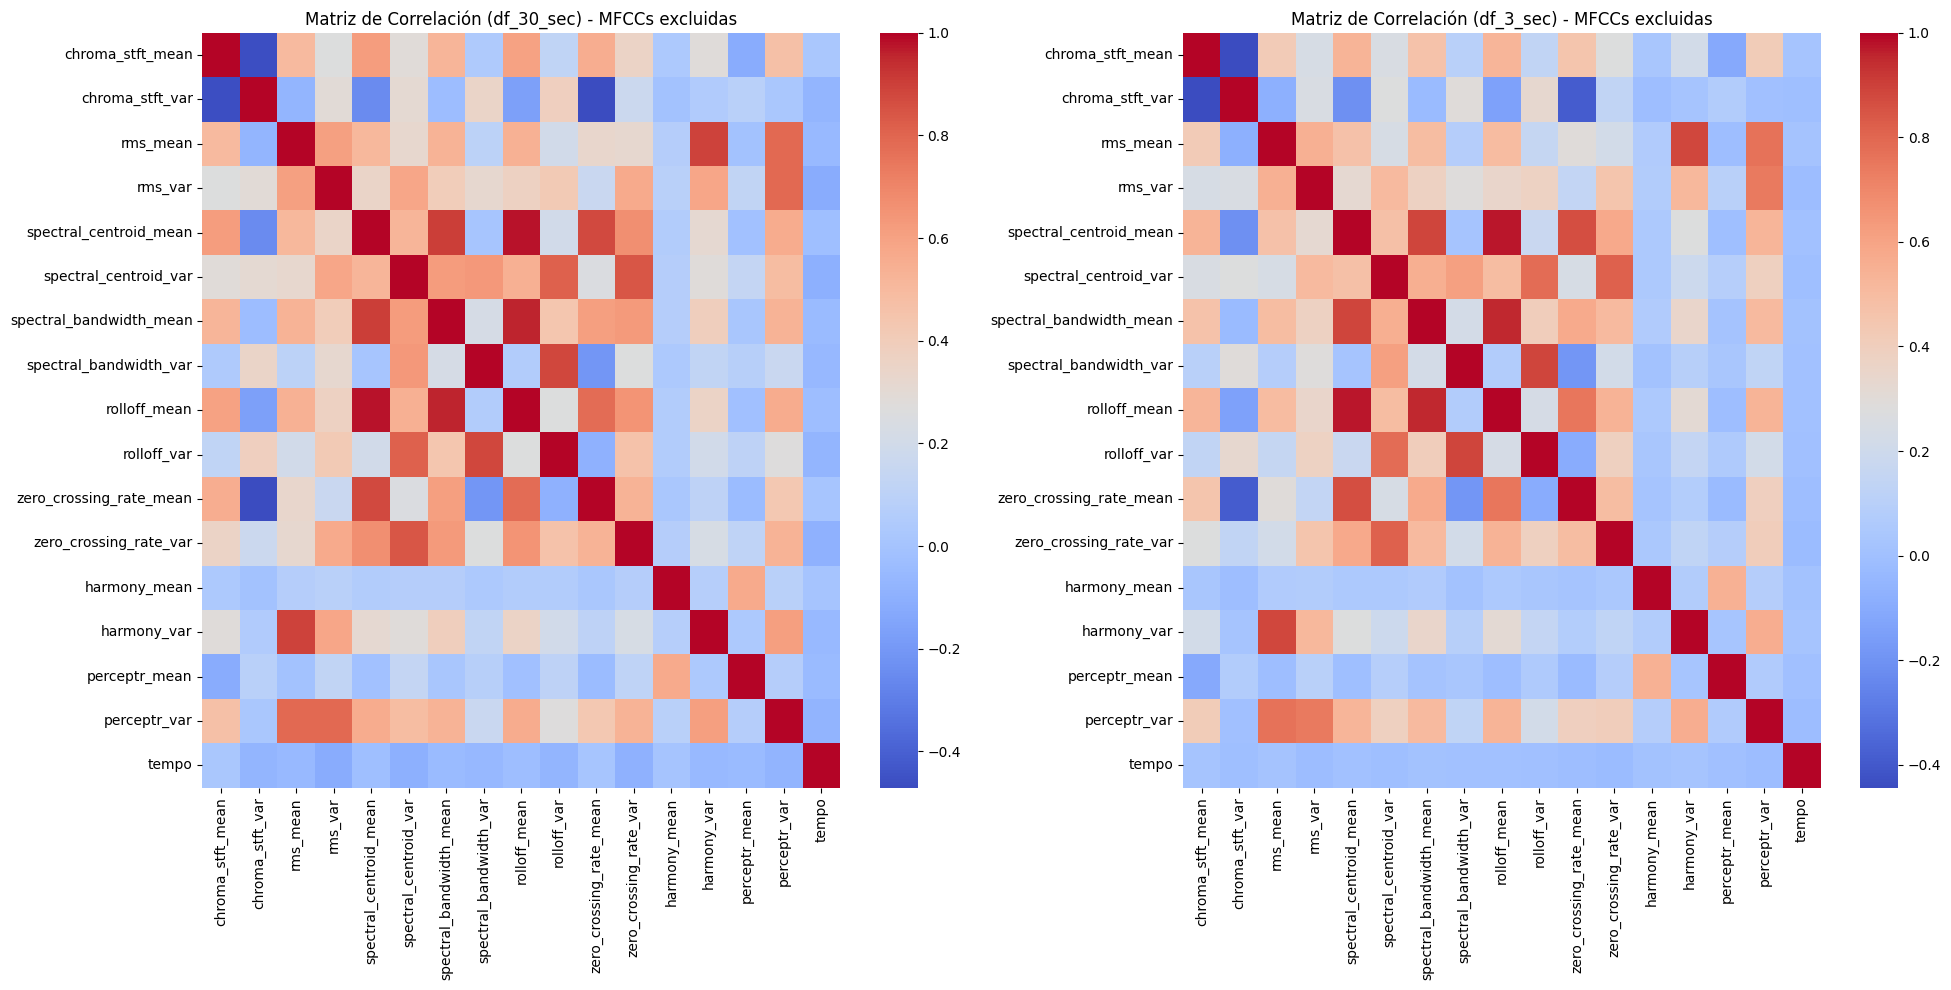

Observaciones sobre las matrices de correlación (sin MFCCs):
La exclusión de las MFCCs permite una visualización más clara de las correlaciones entre las características restantes.
Podemos buscar diferencias notables en la fuerza o dirección de las correlaciones entre los segmentos de 30 segundos y 3 segundos. Por ejemplo, algunas características pueden tener una correlación más fuerte o más débil en segmentos más cortos debido a la captura de eventos más transitorios.


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# Excluir columnas no numéricas y las de 'length' si no se desea ver su correlación directa
columns_to_exclude = ['filename', 'label', 'original_filename', 'length', 'length_in_seconds']

# Añadir todas las columnas mfcc_mean y mfcc_var de 1 a 20 a la lista de exclusión
for i in range(1, 21):
    columns_to_exclude.append(f'mfcc{i}_mean')
    columns_to_exclude.append(f'mfcc{i}_var')

df_30_sec_numeric = df_30_sec.drop(columns=columns_to_exclude, errors='ignore')
df_3_sec_numeric = df_3_sec.drop(columns=columns_to_exclude, errors='ignore')

# Calcular las matrices de correlación
corr_30_sec = df_30_sec_numeric.corr()
corr_3_sec = df_3_sec_numeric.corr()

plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
sns.heatmap(corr_30_sec, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Matriz de Correlación (df_30_sec) - MFCCs excluidas')

plt.subplot(1, 2, 2)
sns.heatmap(corr_3_sec, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Matriz de Correlación (df_3_sec) - MFCCs excluidas')

plt.tight_layout()
plt.show()

print("Observaciones sobre las matrices de correlación (sin MFCCs):")
print("La exclusión de las MFCCs permite una visualización más clara de las correlaciones entre las características restantes.")
print("Podemos buscar diferencias notables en la fuerza o dirección de las correlaciones entre los segmentos de 30 segundos y 3 segundos. Por ejemplo, algunas características pueden tener una correlación más fuerte o más débil en segmentos más cortos debido a la captura de eventos más transitorios.")

### Comparación de Distribuciones de Características Clave

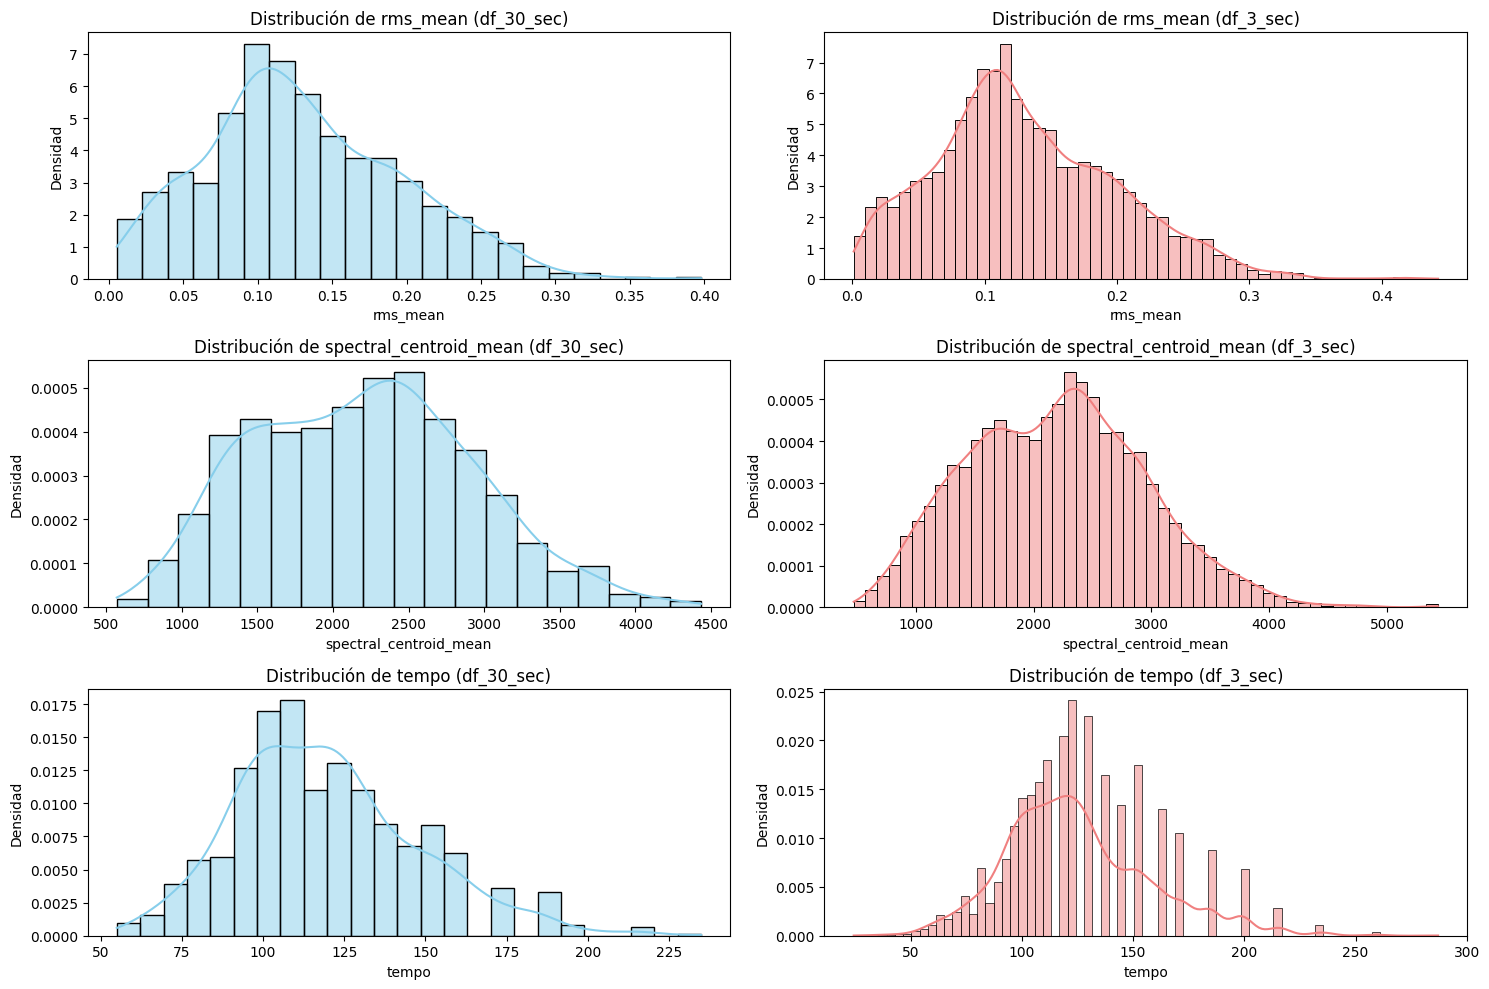

Observaciones sobre las distribuciones:
- `rms_mean`: Representa la energía del sonido. Los segmentos de 3 segundos muestran una distribución más amplia, lo que podría indicar más variabilidad en la energía de fragmentos cortos.
- `spectral_centroid_mean`: Indica el "centro de masa" del espectro, relacionado con el brillo del sonido. Es posible que los segmentos más cortos capturen picos de brillo o momentos más oscuros que se promedian en los segmentos más largos.
- `tempo`: La velocidad percibida de la música. La distribución podría ser más dispersa o concentrada dependiendo de si los segmentos cortos capturan fluctuaciones temporales o si los segmentos largos promedian el tempo general.

Estas visualizaciones nos ayudan a entender cómo la granularidad de los datos afecta la distribución de las características extraídas.


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar algunas características numéricas clave para la comparación
key_features = ['rms_mean', 'spectral_centroid_mean', 'tempo']

plt.figure(figsize=(15, 10))

for i, feature in enumerate(key_features):
    # Histograma para df_30_sec
    plt.subplot(len(key_features), 2, 2*i + 1)
    sns.histplot(df_30_sec[feature], kde=True, color='skyblue', stat='density')
    plt.title(f'Distribución de {feature} (df_30_sec)')
    plt.xlabel(feature)
    plt.ylabel('Densidad')

    # Histograma para df_3_sec
    plt.subplot(len(key_features), 2, 2*i + 2)
    sns.histplot(df_3_sec[feature], kde=True, color='lightcoral', stat='density')
    plt.title(f'Distribución de {feature} (df_3_sec)')
    plt.xlabel(feature)
    plt.ylabel('Densidad')

plt.tight_layout()
plt.show()

print('Observaciones sobre las distribuciones:')
print('- `rms_mean`: Representa la energía del sonido. Los segmentos de 3 segundos muestran una distribución más amplia, lo que podría indicar más variabilidad en la energía de fragmentos cortos.')
print('- `spectral_centroid_mean`: Indica el "centro de masa" del espectro, relacionado con el brillo del sonido. Es posible que los segmentos más cortos capturen picos de brillo o momentos más oscuros que se promedian en los segmentos más largos.')
print('- `tempo`: La velocidad percibida de la música. La distribución podría ser más dispersa o concentrada dependiendo de si los segmentos cortos capturan fluctuaciones temporales o si los segmentos largos promedian el tempo general.')
print('\nEstas visualizaciones nos ayudan a entender cómo la granularidad de los datos afecta la distribución de las características extraídas.')

In [57]:
df_cancion = pd.read_csv(DATA_PROCESSED / "cancion.csv")
display(df_cancion.head())

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,1,blues.00000.wav,00:02:18,744.01,1,1,1,1
1,2,blues.00001.wav,00:02:22,4178.85,1,2,2,2
2,3,blues.00002.wav,00:01:36,3226.40,1,3,4,3
3,4,blues.00003.wav,00:01:51,3618.77,1,4,6,4
4,5,blues.00004.wav,00:03:11,1990.81,1,5,7,5


In [61]:
# 1. Convertir 'duracion' de df_cancion a segundos
# Convertir la columna a string type para manejar posibles floats (NaNs)
df_cancion['duracion_seconds'] = df_cancion['duracion'].astype(str).apply(
    lambda x: sum(int(t) * 60 ** i for i, t in enumerate(reversed(x.split(':'))))
    if ':' in x else 0 # Si es 'nan' u otra cadena que no es formato de tiempo, tratar como 0 segundos
)

# 2. Preparar df_3_sec: Crear una columna base para el nombre del archivo original
#    Ejemplo: 'blues.00000.0.wav' -> 'blues.00000.wav'
df_3_sec['original_filename_base'] = df_3_sec['filename'].apply(lambda x: '.'.join(x.split('.')[:-2]) + '.wav')

# 3. Fusionar df_cancion con df_30_sec
#    Aquí tomamos 'cancion' de df_cancion y 'filename' de df_30_sec, ambos representan la canción completa.
merged_full_song_info = pd.merge(
    df_cancion[['cancion', 'duracion_seconds']],
    df_30_sec[['filename', 'length_in_seconds']],
    left_on='cancion',
    right_on='filename',
    how='inner'
)
merged_full_song_info = merged_full_song_info.rename(columns={'length_in_seconds': 'length_in_seconds_30_sec'})
merged_full_song_info = merged_full_song_info.drop(columns=['filename'])

# 4. Mostrar las primeras filas del DataFrame combinado
print("Datos de duración de canciones (df_cancion) y longitud de 30s (df_30_sec):")
display(merged_full_song_info.head())

print("\nVerificando la longitud de los segmentos de 3 segundos (df_3_sec):")
display(df_3_sec['length_in_seconds'].value_counts())

Datos de duración de canciones (df_cancion) y longitud de 30s (df_30_sec):


,cancion,duracion_seconds,length_in_seconds_30_sec
0,blues.00000.wav,138,30.013333
1,blues.00001.wav,142,30.013333
2,blues.00002.wav,96,30.013333
3,blues.00003.wav,111,30.013333
4,blues.00004.wav,191,30.013333



Verificando la longitud de los segmentos de 3 segundos (df_3_sec):


,count
length_in_seconds,
2.999955,9990


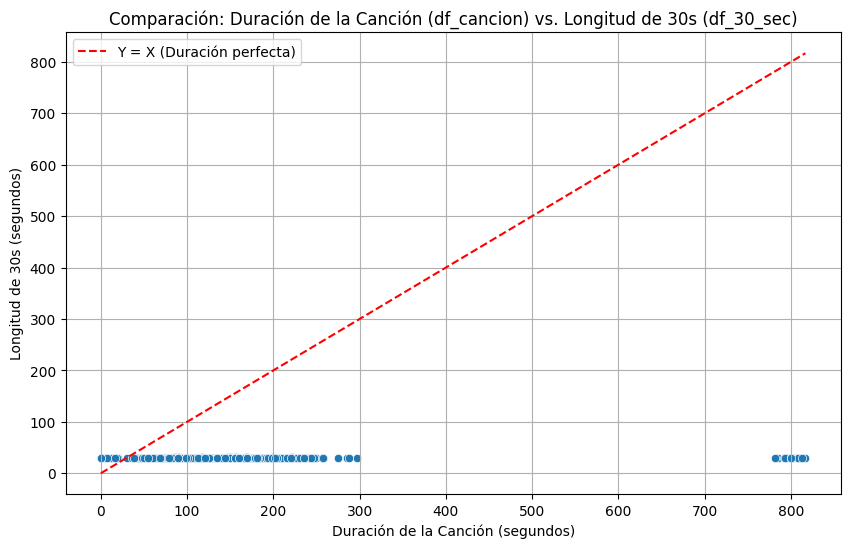

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=merged_full_song_info,
    x='duracion_seconds',
    y='length_in_seconds_30_sec'
)
plt.plot(
    [merged_full_song_info['duracion_seconds'].min(), merged_full_song_info['duracion_seconds'].max()],
    [merged_full_song_info['duracion_seconds'].min(), merged_full_song_info['duracion_seconds'].max()],
    color='red', linestyle='--', label='Y = X (Duración perfecta)'
)
plt.title('Comparación: Duración de la Canción (df_cancion) vs. Longitud de 30s (df_30_sec)')
plt.xlabel('Duración de la Canción (segundos)')
plt.ylabel('Longitud de 30s (segundos)')
plt.legend()
plt.grid(True)
plt.show()


### Análisis de la Diferencia entre la Duración de la Canción y la Longitud de 30s

Vamos a calcular la diferencia entre `duracion_seconds` (la duración original de la canción) y `length_in_seconds_30_sec` (la longitud del segmento de 30 segundos utilizado para la extracción de características). Visualizar esta diferencia nos ayudará a entender cuánto de la canción original está siendo 'cubierta' por el segmento de 30 segundos, o si hay una discrepancia constante.

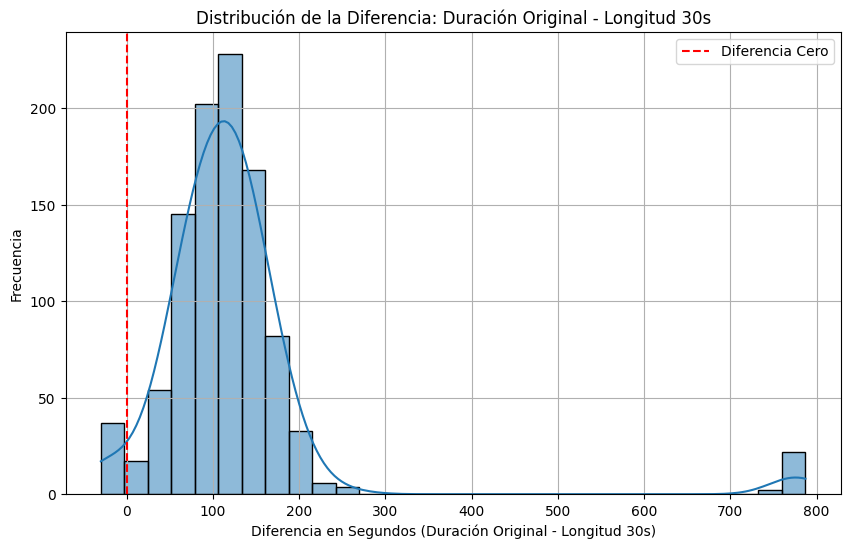

count    1000.000000
mean      123.056925
std       113.689621
min       -30.013333
25%        77.996531
50%       111.993243
75%       142.986667
max       786.999819
Name: duration_diff, dtype: float64


In [67]:
merged_full_song_info['duration_diff'] = merged_full_song_info['duracion_seconds'] - merged_full_song_info['length_in_seconds_30_sec']

plt.figure(figsize=(10, 6))
sns.histplot(merged_full_song_info['duration_diff'], kde=True, bins=30)
plt.title('Distribución de la Diferencia: Duración Original - Longitud 30s')
plt.xlabel('Diferencia en Segundos (Duración Original - Longitud 30s)')
plt.ylabel('Frecuencia')
plt.axvline(0, color='red', linestyle='--', label='Diferencia Cero')
plt.legend()
plt.grid(True)
plt.show()

print(merged_full_song_info['duration_diff'].describe())